# Ablation: full Hao reference without the HaoSub cells

In [1]:
from pathlib import Path
import sys

LOCAL_RECTANGLE = Path('/Users/berni/PycharmProjects/Rectangle')
local_src = LOCAL_RECTANGLE / 'src'
if not (local_src / 'rectanglepy' / '__init__.py').is_file():
    raise FileNotFoundError(f'Rectangle source not found: {local_src}')
loaded_rectangle = sys.modules.get('rectanglepy')
if loaded_rectangle is not None and not Path(loaded_rectangle.__file__).resolve().is_relative_to(local_src.resolve()):
    raise RuntimeError('Restart the kernel to load the local Rectangle source.')
if str(local_src) in sys.path:
    sys.path.remove(str(local_src))
sys.path.insert(0, str(local_src))
import rectanglepy as rp
if not Path(rp.__file__).resolve().is_relative_to(local_src.resolve()):
    raise RuntimeError(f'Wrong Rectangle source: {rp.__file__}')
print(f'Rectangle source: {rp.__file__}', flush=True)

import hashlib
import anndata
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, issparse
import helper

Rectangle source: /Users/berni/PycharmProjects/Rectangle/src/rectanglepy/__init__.py


## Hyperparameter sensitivity

Results use the **2026-10-08 rerun**, with all 432 configurations on Finotello and the full Hao reference excluding HaoSub cells. The ranked CSV is saved in `../data/ablation/finotello_hyperparameter_search_hao_disjoint_rerun_2026_10_08.csv` and matches the CSV embedded in [the source rankings](file:///Users/berni/PycharmProjects/rectangle_benchmark/output/finotello_hyperparameter_search_hao_disjoint_rerun_2026_10_08/standalone/finotello_rankings.html).

All nine samples were used for tuning. The best configuration below is selected by combined correlation and RMSE rank.

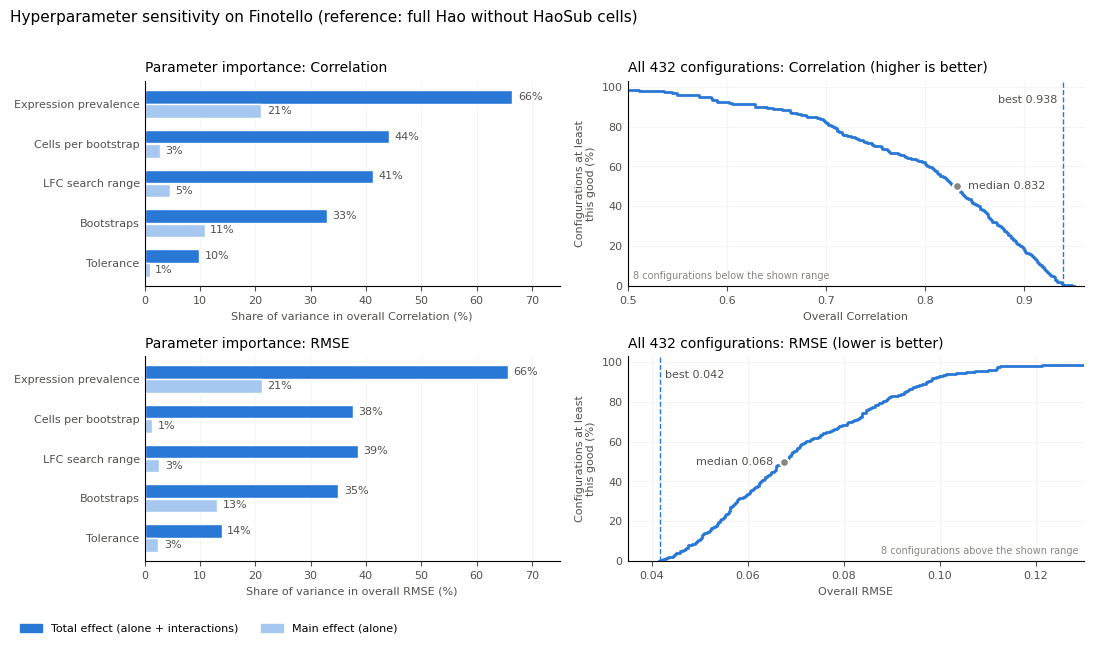

Share of configurations with r >= 0.9: 19%; within 0.01 of the best r: 5%


,Correlation main effect (%),Correlation total effect (%),RMSE main effect (%),RMSE total effect (%)
parameter,,,,
Expression prevalence,21.1,66.5,21.2,65.7
Cells per bootstrap,2.7,44.2,1.4,37.6
LFC search range,4.5,41.3,2.7,38.5
Bootstraps,10.9,33.0,13.1,35.0
Tolerance,0.9,9.8,2.5,13.9


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Results from the 2026-10-08 rerun (CSV matches finotello_rankings.html).
# the grid is a full factorial (3 x 4 x 3 x 3 x 4 = 432), so variance shares come straight from group means:
# main effect  = Var(E[Y | parameter]) / Var(Y)            -> the parameter alone
# total effect = 1 - Var(E[Y | all other parameters]) / Var(Y) -> the parameter plus all its interactions
grid = pd.read_csv('../data/ablation/finotello_hyperparameter_search_hao_disjoint_rerun_2026_10_08.csv')
best = grid.loc[grid['combined_position'].idxmin()]
parameter_names = {
    'prevalence': 'Expression prevalence',
    'cells_per_bootstrap': 'Cells per bootstrap',
    'lfc_range': 'LFC search range',
    'bootstraps': 'Bootstraps',
    'tolerance': 'Tolerance',
}
metrics = [('overall_correlation', 'Correlation'), ('overall_rmse', 'RMSE')]

def variance_shares(metric):
    total_variance = grid[metric].var(ddof=0)
    rows = []
    for parameter in parameter_names:
        others = [p for p in parameter_names if p != parameter]
        main = grid.groupby(parameter)[metric].transform('mean').var(ddof=0) / total_variance
        total = 1 - grid.groupby(others)[metric].transform('mean').var(ddof=0) / total_variance
        rows.append((parameter, main, total))
    return pd.DataFrame(rows, columns=['parameter', 'main', 'total']).set_index('parameter')

sensitivity = pd.concat({metric: variance_shares(metric) for metric, _ in metrics}, axis=1)
order = sensitivity[('overall_correlation', 'total')].sort_values().index  # largest at the top

total_color, main_color, ink, muted = '#2a78d6', '#a6c8f0', '#52514e', '#898781'
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), facecolor='white', gridspec_kw={'width_ratios': [1, 1.1]})

for row, (metric, metric_name) in enumerate(metrics):
    # left: how much of the variance across the grid each parameter explains
    ax = axes[row, 0]
    shares = sensitivity[metric].loc[order] * 100
    y = np.arange(len(order))
    ax.barh(y + 0.18, shares['total'], height=0.34, color=total_color, edgecolor='white', linewidth=1)
    ax.barh(y - 0.18, shares['main'], height=0.34, color=main_color, edgecolor='white', linewidth=1)
    for yi, (total, main) in enumerate(zip(shares['total'], shares['main'])):
        ax.annotate(f'{total:.0f}%', (total, yi + 0.18), xytext=(4, 0), textcoords='offset points',
                    va='center', fontsize=8, color=ink)
        ax.annotate(f'{main:.0f}%', (main, yi - 0.18), xytext=(4, 0), textcoords='offset points',
                    va='center', fontsize=8, color=ink)
    ax.set_yticks(y)
    ax.set_yticklabels([parameter_names[p] for p in order], fontsize=9)
    ax.set_xlim(0, 75)
    ax.set_xlabel(f'Share of variance in overall {metric_name} (%)', fontsize=8, color=ink)
    ax.set_title(f'Parameter importance: {metric_name}', fontsize=10, loc='left')
    ax.grid(axis='x', color='#eeede9', linewidth=0.8)
    ax.set_axisbelow(True)

    # right: share of all 432 configurations that are at least as good as a given value
    ax = axes[row, 1]
    values = np.sort(grid[metric].to_numpy())
    if metric == 'overall_correlation':
        share_as_good = 1 - np.arange(len(values)) / len(values)          # share with r >= value
    else:
        share_as_good = np.arange(1, len(values) + 1) / len(values)        # share with RMSE <= value
    ax.step(values, share_as_good * 100, where='post' if metric == 'overall_rmse' else 'pre',
            color=total_color, linewidth=2)
    median = grid[metric].median()
    lower_is_better = metric == 'overall_rmse'
    inward = 1 if lower_is_better else -1  # labels sit on the side facing the bulk of the curve
    ax.axvline(best[metric], color=total_color, linestyle='--', linewidth=1)
    ax.annotate(f'best {best[metric]:.3f}', (best[metric], 96), xytext=(4 * inward, 0), textcoords='offset points',
                ha='left' if lower_is_better else 'right', va='top', fontsize=8, color=ink)
    ax.scatter([median], [50], s=40, color=muted, edgecolor='white', linewidth=1.5, zorder=3)
    ax.annotate(f'median {median:.3f}', (median, 50), xytext=(-8 * inward, 0), textcoords='offset points',
                ha='right' if lower_is_better else 'left', va='center', fontsize=8, color=ink)
    low, high = (0.5, 0.96) if metric == 'overall_correlation' else (0.035, 0.13)
    outside = int(((grid[metric] < low) | (grid[metric] > high)).sum())
    ax.set_xlim(low, high)
    ax.annotate(f'{outside} configurations {"above" if lower_is_better else "below"} the shown range',
                (1 if lower_is_better else 0, 0), xycoords='axes fraction', xytext=(-4 * inward, 4),
                textcoords='offset points', ha='right' if lower_is_better else 'left', va='bottom',
                fontsize=7, color=muted)
    ax.set_ylim(0, 103)
    ax.set_xlabel(f'Overall {metric_name}', fontsize=8, color=ink)
    ax.set_ylabel('Configurations at least' + chr(10) + 'this good (%)', fontsize=8, color=ink)
    direction = 'higher' if metric == 'overall_correlation' else 'lower'
    ax.set_title(f'All 432 configurations: {metric_name} ({direction} is better)', fontsize=10, loc='left')
    ax.grid(color='#eeede9', linewidth=0.8)
    ax.set_axisbelow(True)

for ax in axes.flat:
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=8, colors=ink)
    ax.tick_params(axis='y', length=0)

fig.legend(handles=[Patch(color=total_color, label='Total effect (alone + interactions)'),
                    Patch(color=main_color, label='Main effect (alone)')],
           loc='lower left', ncol=2, frameon=False, fontsize=8, bbox_to_anchor=(0.01, -0.01))
fig.suptitle('Hyperparameter sensitivity on Finotello (reference: full Hao without HaoSub cells)',
             fontsize=11, x=0.01, ha='left')
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.savefig('../output/ablation_fino_parameter_importance.png', dpi=300, bbox_inches='tight')
plt.show()

summary = sensitivity.mul(100).round(1)
summary.columns = [f'{metric_name} {effect} effect (%)' for (metric, effect), metric_name in
                   zip(summary.columns, ['Correlation'] * 2 + ['RMSE'] * 2)]
summary = summary.loc[order[::-1]].rename(index=parameter_names)
summary.to_csv('../output/ablation_fino_parameter_importance.csv')
print(f"Share of configurations with r >= 0.9: {(grid['overall_correlation'] >= 0.9).mean():.0%}; "
      f"within 0.01 of the best r: {(grid['overall_correlation'] >= best['overall_correlation'] - 0.01).mean():.0%}")
summary

### Supplementary: one parameter changed at a time from the best configuration

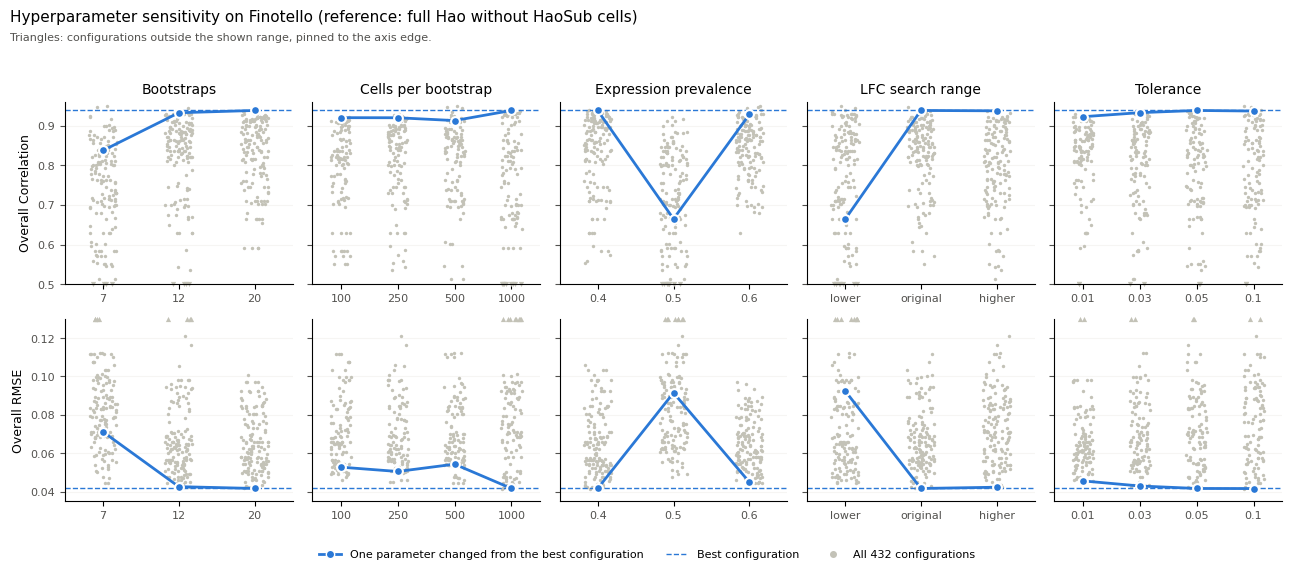

Best configuration: original_b20_c1000_e0.4_t0.05 (r=0.938, RMSE=0.042)


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 432-configuration grid search (Finotello, full Hao without HaoSub), 2026-10-08 rerun.
# Source: rectangle_benchmark/output/finotello_hyperparameter_search_hao_disjoint_rerun_2026_10_08/results_ranked.csv
grid = pd.read_csv('../data/ablation/finotello_hyperparameter_search_hao_disjoint_rerun_2026_10_08.csv')
best = grid.loc[grid['combined_position'].idxmin()]

parameters = [
    ('bootstraps', 'Bootstraps', [7, 12, 20]),
    ('cells_per_bootstrap', 'Cells per bootstrap', [100, 250, 500, 1000]),
    ('prevalence', 'Expression prevalence', [0.4, 0.5, 0.6]),
    ('lfc_range', 'LFC search range', ['lower', 'original', 'higher']),
    ('tolerance', 'Tolerance', [0.01, 0.03, 0.05, 0.1]),
]
metrics = [
    ('overall_correlation', 'Correlation', (0.5, 0.96)),
    ('overall_rmse', 'RMSE', (0.035, 0.13)),
]

# one-at-a-time: change one parameter from the best configuration, hold the other four fixed
def neighbourhood(parameter):
    others = [p for p, _, _ in parameters if p != parameter]
    rows = grid[(grid[others] == best[others]).all(axis=1)]
    return rows.set_index(parameter)

best_color, grid_color, line_color, ink = '#2a78d6', '#c3c2b7', '#2a78d6', '#52514e'
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, len(parameters), figsize=(13, 5.6), sharey='row', facecolor='white')
for col, (parameter, title, levels) in enumerate(parameters):
    local = neighbourhood(parameter)
    for row, (metric, metric_name, (low, high)) in enumerate(metrics):
        ax = axes[row, col]
        x = np.arange(len(levels))
        for xi, level in zip(x, levels):
            values = grid.loc[grid[parameter] == level, metric].to_numpy()
            # values outside the shared axis are pinned to the edge as triangles
            clipped = np.clip(values, low, high)
            outside = clipped != values
            jitter = rng.uniform(-0.18, 0.18, len(values))
            ax.scatter(xi + jitter[~outside], clipped[~outside], s=6, color=grid_color, linewidth=0, zorder=1)
            if outside.any():
                ax.scatter(xi + jitter[outside], clipped[outside], s=14, color=grid_color, linewidth=0,
                           marker='v' if metric == 'overall_correlation' else '^', zorder=1, clip_on=False)
        ax.axhline(best[metric], color=best_color, linestyle='--', linewidth=1, zorder=2)
        ax.plot(x, local.loc[levels, metric], color=line_color, linewidth=2, zorder=3)
        ax.scatter(x, local.loc[levels, metric], s=40, color=line_color, edgecolor='white', linewidth=1.5, zorder=4)
        ax.set_ylim(low, high)
        ax.set_xticks(x)
        ax.set_xticklabels([str(level) for level in levels], fontsize=8, color=ink)
        ax.set_xlim(-0.5, len(levels) - 0.5)
        ax.grid(axis='y', color='#eeede9', linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        ax.tick_params(axis='y', labelsize=8, colors=ink)
        if row == 0:
            ax.set_title(title, fontsize=10)
        if col == 0:
            ax.set_ylabel(f'Overall {metric_name}', fontsize=9)

legend_handles = [
    Line2D([], [], color=line_color, linewidth=2, marker='o', markersize=6, markeredgecolor='white',
           label='One parameter changed from the best configuration'),
    Line2D([], [], color=best_color, linestyle='--', linewidth=1, label='Best configuration'),
    Line2D([], [], color=grid_color, linestyle='none', marker='o', markersize=4, label='All 432 configurations'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=3, frameon=False, fontsize=8,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Hyperparameter sensitivity on Finotello (reference: full Hao without HaoSub cells)',
             fontsize=11, x=0.01, ha='left')
fig.text(0.01, 0.925, 'Triangles: configurations outside the shown range, pinned to the axis edge.', fontsize=8, color=ink)
plt.tight_layout(rect=(0, 0.04, 1, 0.93))
plt.savefig('../output/ablation_fino_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Best configuration: {best['configuration']} "
      f"(r={best['overall_correlation']:.3f}, RMSE={best['overall_rmse']:.3f})")

# Cell-type level ablation on all Figure 2 datasets

Same references as Figure 2: **HaoSub** for the human datasets (Finotello, Hoek, Morandini, Dietrich) and **Tabula Muris** for the mouse datasets (Chen, Petitprez).

How to run:
1. **Restart the kernel**, then run the setup cell below (skip the cells above it). It uses the released **rectanglepy 1.7.0** installed from PyPI and stops if the local Rectangle checkout is loaded.
2. Run each ablation cell. Every cell deconvolves all six datasets and writes `../output/ablation_hao_sub_rectangle_1_7_0/<ablation>/<dataset>.csv`.
3. No manual source changes are needed: hierarchy and condition-number ablations temporarily override the relevant signature step and restore it when the cell finishes or fails.
4. The evaluation and plot cells only read the saved CSVs, so they can be run in a fresh kernel. Missing ablations are skipped with a warning.

The `no_unknown` ablation uses `correct_unknown_fraction=False`: unknown correction is disabled and known fractions remain normalized to 1. Other ablations retain default unknown correction.

The `no_condition_number` ablation retains all markers passing the DE cutoffs, rather than choosing a marker count by condition number. This applies during cutoff tuning and to direct and clustered signatures. The `no_hierarchy` ablation skips clustered signatures and uses direct deconvolution.

In [1]:
from pathlib import Path
import sys

# Use the released rectanglepy 1.7.0 installed from PyPI in this environment, not the local Rectangle checkout
REQUIRED_RECTANGLE = '1.7.0'
local_src = Path('/Users/berni/PycharmProjects/Rectangle/src').resolve()
sys.path = [p for p in sys.path if Path(p or '.').resolve() != local_src]
loaded_rectangle = sys.modules.get('rectanglepy')
if loaded_rectangle is not None and Path(loaded_rectangle.__file__).resolve().is_relative_to(local_src):
    raise RuntimeError('rectanglepy was already imported from the local checkout (cell at the top). Restart the kernel and start here.')
import rectanglepy as rp
if rp.__version__ != REQUIRED_RECTANGLE or 'site-packages' not in Path(rp.__file__).parts:
    raise RuntimeError(f'Expected installed rectanglepy {REQUIRED_RECTANGLE}, got {rp.__version__} from {rp.__file__}. '
                       f'Install it with: uv pip install --python ../.venv/bin/python rectanglepy=={REQUIRED_RECTANGLE}')
print(f'rectanglepy {rp.__version__}: {rp.__file__}', flush=True)

import anndata
import numpy as np
import pandas as pd
from anndata import AnnData
import helper

ablation_root = Path('../output/ablation_hao_sub_rectangle_1_7_0')

adata_hao_sub = anndata.read_h5ad('../data/fig2/haoSub_adata.h5ad')
sc_data_muris = pd.read_pickle('../data/sc_data_tabula_muris.pkl.zip')
annotations_muris = pd.read_csv('../data/annotations_tabula_muris.csv', index_col=0)['0']
annotations_muris = pd.Series(annotations_muris, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations_muris.to_frame(name='cell_type'))

# dataset -> (reference, bulks as samples x genes), same pairing as figure_2.ipynb
ablation_datasets = {
    'finotello': (adata_hao_sub, pd.read_csv('../data/fig2/finotello/bulks_finotello_tpm.csv', index_col=0).T),
    'petitprez': (adata_muris, pd.read_csv('../data/fig2/bulks/bulks_petitprez_tpm.csv', index_col=0).T),
    'chen': (adata_muris, pd.read_csv('../data/fig2/bulks/bulks_chen_tpm.csv', index_col=0).T),
    'hoek': (adata_hao_sub, pd.read_csv('../data/fig2/bulks/bulks_hoek_tpm.csv', index_col=0).T),
    'morandini': (adata_hao_sub, pd.read_csv('../data/fig2/morandini/morandini_rework_tpm.csv.gz', index_col=0).T),
    'dietrich': (adata_hao_sub, pd.read_csv('../data/fig2/deconvMe/dietrich_tpm.csv', index_col=0).T),
}

def run_ablation(ablation, datasets=None, **rectangle_kwargs):
    out_dir = ablation_root / ablation
    out_dir.mkdir(parents=True, exist_ok=True)
    for dataset in datasets or ablation_datasets:
        reference, bulks = ablation_datasets[dataset]
        print(f'--- {ablation}: {dataset}')
        estimations, _ = rp.rectangle(reference, bulks, **rectangle_kwargs)
        estimations.to_csv(out_dir / f'{dataset}.csv')

rectanglepy 1.7.0: /Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/rectanglepy/__init__.py


In [3]:
# Full Rectangle (default settings), rerun with rectanglepy 1.7.0 so every variant uses the same release
run_ablation('full')

--- full: finotello


2026-10-14 12:20:19.457 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-14 12:20:21.926 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-14 12:20:26.232 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-14 12:20:31.175 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-14 12:20:33.852 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-14 12:20:37.202 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-14 12:20:39.486 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-14 12:20:41.476 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-14

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-14 12:20:52.776 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40
2026-10-14 12:20:53.048 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.027472426488265998, Pearson R:0.9123159469511136 for p=0.05, lfc=1.7


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


...

2026-10-14 12:24:42.075 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 42
2026-10-14 12:24:42.092 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 33
2026-10-14 12:24:42.118 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 43
2026-10-14 12:24:42.157 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 36
2026-10-14 12:24:42.181 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 44
2026-10-14 12:24:42.195 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 37
2026-10-14 12:24:42.217 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 45


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:24:42.329 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 38
2026-10-14 12:24:42.350 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 46
2026-10-14 12:24:42.351 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 39
2026-10-14 12:24:42.365 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 47
2026-10-14 12:24:42.602 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 40
2026-10-14 12:24:42.623 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 48
2026-10-14 12:24:42.677 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 41
2026-10-14 12:24:42.696 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 49
2026-10-14 12:24:42.781 | IN

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:24:42.813 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 51
2026-10-14 12:24:42.828 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 52
2026-10-14 12:24:42.926 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 44
2026-10-14 12:24:42.945 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 53
2026-10-14 12:24:43.058 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 46
2026-10-14 12:24:43.080 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 54
2026-10-14 12:24:43.154 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 47
2026-10-14 12:24:43.175 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 55
2026-10-14 12:24:43.317 | INF

In [4]:
run_ablation('no_mrna_bias', correct_mrna_bias=False)

--- no_mrna_bias: finotello


2026-10-14 12:24:50.584 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-14 12:24:53.154 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-14 12:24:57.017 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-14 12:24:58.144 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-14 12:24:59.703 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-14 12:25:01.410 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-14 12:25:02.568 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-14 12:25:03.615 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-14

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:25:13.013 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.027472426488265998, Pearson R:0.9123159469511136 for p=0.05, lfc=1.7
2026-10-14 12:25:13.100 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40
2026-10-14 12:25:13.193 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02754013312534663, Pearson R:0.9124773032955845 for p=0.05, lfc=1.8


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


...

2026-10-14 12:28:55.903 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.0998098336419541, Pearson R:0.3670103216260942 for p=0.05, lfc=2.1
2026-10-14 12:28:56.016 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 21
2026-10-14 12:28:56.217 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.10089664969224987, Pearson R:0.3582431746130027 for p=0.05, lfc=2.2
2026-10-14 12:28:56.219 | INFO     | rectanglepy.pp.create_signature:_de_analysis:232 - Optimization done
 Best cutoffs  p: 0.05 and lfc: 1.6


Polishing not needed - no active set detected at optimal point


2026-10-14 12:28:56.336 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 77
2026-10-14 12:28:56.341 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:385 - Starting rectangle cluster analysis
2026-10-14 12:28:56.355 | INFO     | rectanglepy.pp.create_signature:_create_clustered_data:290 - Starting clustered analysis
2026-10-14 12:28:58.160 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-14 12:29:02.347 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 1
2026-10-14 12:29:04.421 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 2
2026-10-14 12:29:06.420 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 5
2026-10-14 12:29:08.351 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-14 12:29:09.850 | INFO     | rectanglep

Polishing not needed - no active set detected at optimal point


2026-10-14 12:29:18.068 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 16
2026-10-14 12:29:18.113 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 24
2026-10-14 12:29:18.213 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 17
2026-10-14 12:29:18.235 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 25
2026-10-14 12:29:18.367 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 18
2026-10-14 12:29:18.396 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 26
2026-10-14 12:29:18.434 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 19
2026-10-14 12:29:18.441 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 20
2026-10-14 12:29:18.453 | I

In [5]:
run_ablation('no_grid_search', optimize_cutoffs=False, lfc=2.0,p=0.05)

--- no_grid_search: finotello


2026-10-14 12:29:26.200 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-14 12:29:28.637 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-14 12:29:33.207 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-14 12:29:34.447 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-14 12:29:36.527 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-14 12:29:38.510 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-14 12:29:39.916 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-14 12:29:41.141 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-14

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:30:08.294 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 2
2026-10-14 12:30:08.298 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 7
2026-10-14 12:30:08.311 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 3
2026-10-14 12:30:08.312 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 8
2026-10-14 12:30:08.328 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 1
2026-10-14 12:30:08.329 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 0
2026-10-14 12:30:08.348 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 4
2026-10-14 12:30:08.364 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 5
2026-10-14 12:30:08.366 | INFO   

Polishing not needed - no active set detected at optimal point


...

2026-10-14 12:33:33.054 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 41
2026-10-14 12:33:33.070 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 40
2026-10-14 12:33:33.078 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 48
2026-10-14 12:33:33.112 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 49
2026-10-14 12:33:33.167 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 42
2026-10-14 12:33:33.194 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 50
2026-10-14 12:33:33.195 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 45
2026-10-14 12:33:33.195 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 44
2026-10-14 12:33:33.207 | I

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:33:33.494 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 48
2026-10-14 12:33:33.526 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 56
2026-10-14 12:33:33.537 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 49
2026-10-14 12:33:33.568 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 57
2026-10-14 12:33:33.621 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 50
2026-10-14 12:33:33.624 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 51
2026-10-14 12:33:33.638 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 52
2026-10-14 12:33:33.643 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 58
2026-10-14 12:33:33.696 | I

Polishing not needed - no active set detected at optimal point


2026-10-14 12:33:33.779 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 54
2026-10-14 12:33:33.786 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 55
2026-10-14 12:33:33.923 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 56
2026-10-14 12:33:33.948 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 57
2026-10-14 12:33:34.000 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 58
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [6]:
# Disable unknown fraction correction; known fractions still sum to 1.
run_ablation('no_unknown', correct_unknown_fraction=False)

--- no_unknown: finotello


2026-10-14 12:33:38.433 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-14 12:33:41.498 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-14 12:33:45.572 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-14 12:33:46.867 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-14 12:33:49.084 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-14 12:33:51.166 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-14 12:33:52.562 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-14 12:33:53.795 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-14

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:34:05.274 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.027472426488265998, Pearson R:0.9123159469511136 for p=0.05, lfc=1.7
2026-10-14 12:34:05.380 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


...

2026-10-14 12:38:03.033 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 35
2026-10-14 12:38:03.039 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 34
2026-10-14 12:38:03.058 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 42
2026-10-14 12:38:03.067 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 43
2026-10-14 12:38:03.142 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 36
2026-10-14 12:38:03.159 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 37
2026-10-14 12:38:03.174 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 44
2026-10-14 12:38:03.204 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 45


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:38:03.303 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 38
2026-10-14 12:38:03.312 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 39
2026-10-14 12:38:03.319 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 46
2026-10-14 12:38:03.343 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 47
2026-10-14 12:38:03.715 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 40
2026-10-14 12:38:03.735 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 48
2026-10-14 12:38:03.762 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 41
2026-10-14 12:38:03.792 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 49
2026-10-14 12:38:03.868 | IN

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:38:03.948 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 51
2026-10-14 12:38:04.044 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 45
2026-10-14 12:38:04.060 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 52
2026-10-14 12:38:04.111 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 44
2026-10-14 12:38:04.137 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 53
2026-10-14 12:38:04.182 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 46
2026-10-14 12:38:04.209 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 47
2026-10-14 12:38:04.214 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 54
2026-10-14 12:38:04.245 | IN

In [7]:
# Disable hierarchy only in this cell; direct signatures and unknown correction stay enabled.
import importlib
from unittest.mock import patch

signature_module = importlib.import_module('rectanglepy.pp.create_signature')
with patch.object(
    signature_module, '_create_clustered_data',
    return_value=(pd.DataFrame(), pd.Series(dtype=object), []),
):
    run_ablation('no_hierarchy')


--- no_hierarchy: finotello


2026-10-14 12:38:30.040 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-14 12:38:33.619 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-14 12:38:37.885 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-14 12:38:39.288 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-14 12:38:41.201 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-14 12:38:43.249 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-14 12:38:44.758 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-14 12:38:46.515 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-14

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-14 12:39:01.677 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40
2026-10-14 12:39:01.863 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.027472426488265998, Pearson R:0.9123159469511136 for p=0.05, lfc=1.7


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


...

2026-10-14 12:41:30.641 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 33
2026-10-14 12:41:30.646 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 32
2026-10-14 12:41:30.666 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 40
2026-10-14 12:41:30.669 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 35
2026-10-14 12:41:30.688 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 41
2026-10-14 12:41:30.695 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 34
2026-10-14 12:41:30.699 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 36
2026-10-14 12:41:30.703 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 42
2026-10-14 12:41:30.733 | I

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-14 12:41:30.870 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 47
2026-10-14 12:41:30.941 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 41
2026-10-14 12:41:30.948 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 40
2026-10-14 12:41:30.970 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 48
2026-10-14 12:41:30.975 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 43
2026-10-14 12:41:30.989 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 49
2026-10-14 12:41:30.993 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 42
2026-10-14 12:41:30.999 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 50
2026-10-14 12:41:31.027 | IN

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-14 12:41:31.080 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 45
2026-10-14 12:41:31.092 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 46
2026-10-14 12:41:31.097 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 52
2026-10-14 12:41:31.118 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 53
2026-10-14 12:41:31.146 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 54
2026-10-14 12:41:31.208 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 47
2026-10-14 12:41:31.231 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 50
2026-10-14 12:41:31.231 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:442 - Deconvolute fractions for bulk: 55
2026-10-14 12:41:31.250 | IN

In [8]:
# Disable condition-number selection for this ablation only.
# Keep every marker passing the DE cutoffs, in cutoff tuning and both signatures.
import importlib
from unittest.mock import patch
from loguru import logger

signature_module = importlib.import_module('rectanglepy.pp.create_signature')
condition_ablation_calls = []

def markers_without_condition_number(deseq_results, logfc, p, pseudo_count_sig):
    adjusted = {
        annotation: signature_module._filter_de_analysis_results(result, p, logfc)
        for annotation, result in deseq_results.items()
    }
    max_markers = max(len(result) for result in adjusted.values())
    marker_matrix = signature_module._create_condition_number_matrix(
        adjusted, signature_module._convert_to_cpm(pseudo_count_sig), max_markers,
    )
    markers_per_type = signature_module._get_marker_genes_per_cell_type(adjusted, max_markers)
    condition_ablation_calls.append(len(marker_matrix))
    logger.info(f'Condition-number search disabled: retaining all {len(marker_matrix)} passing marker genes')
    return marker_matrix.index, markers_per_type

# Patching in the signature module covers both cutoff tuning and final marker selection.
# The second patch verifies that the condition-number search is never called.
with patch.object(signature_module, '_get_marker_genes', markers_without_condition_number), patch.object(
    signature_module, '_create_condition_number_matrices',
    side_effect=AssertionError('Condition-number search must be disabled in this ablation'),
):
    run_ablation('no_condition_number')
assert condition_ablation_calls, 'The condition-number ablation was not applied'
print(f'Condition-number selection bypassed in {len(condition_ablation_calls)} marker selections')


--- no_condition_number: finotello


2026-10-14 12:41:37.749 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-14 12:41:40.847 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-14 12:41:45.162 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-14 12:41:48.176 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-14 12:41:51.127 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-14 12:41:54.759 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-14 12:41:56.933 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-14 12:41:58.500 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-14

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-14 12:42:09.626 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.03037411179019597, Pearson R:0.8902771681274124 for p=0.05, lfc=1.7
2026-10-14 12:42:09.633 | INFO     | __main__:markers_without_condition_number:21 - Condition-number search disabled: retaining all 980 passing marker genes


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


...

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-14 12:46:53.151 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 55


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-14 12:46:53.993 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 57
2026-10-14 12:46:54.010 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 56
2026-10-14 12:46:54.019 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:450 - Finished deconvolution for bulk: 58
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Condition-number selection bypassed in 54 marker selections


## Evaluation per cell type

Gold standards and cell type matching are the same as in `figure_2.ipynb`. Every `prepare_*` function returns `(gold, estimated)` as cell types x samples with identical row and column order.

RMSE and correlation use the same finite pairs. Missing/infinite estimates are excluded and counted in `n_valid_pairs` and `n_total_pairs`; affected datasets are reported in `evaluation_issues.csv`. Runs with no valid pairs retain undefined scores, and correlation is undefined for fewer than two pairs or constant vectors. Failed estimates are never filled with zero.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import helper
from scipy.stats import pearsonr

ablation_root = Path('../output/ablation_hao_sub_rectangle_1_7_0')
ablation_order = ['full', 'no_mrna_bias', 'no_grid_search', 'no_unknown', 'no_hierarchy', 'no_condition_number']
dataset_order = ['finotello', 'petitprez', 'chen', 'hoek', 'morandini', 'dietrich']


def aligned(gold, estimated):
    gold, estimated = helper.match_dfs(gold, estimated)
    gold = gold.sort_index(key=lambda x: x.str.lower())
    return gold, estimated.loc[gold.index, gold.columns]


def prepare_finotello(estimations):
    gold = pd.read_csv('../data/finotello_facs.csv', index_col=0).T.fillna(0)
    gold.columns = ['NK cells', 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                    'T cells CD4 conv', 'Other']
    return aligned(gold.T, estimations.T)


def prepare_petitprez(estimations):
    gold = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T.fillna(0)
    gold.columns = ['T cells', 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                    'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                    'Granulocytes']
    gold = gold.drop(columns=['T cells'])
    return aligned(gold.T, estimations.T)


def prepare_chen(estimations):
    gold = pd.read_csv('../data/chen_facs.csv', index_col=0).T.fillna(0)
    gold.columns = ['Monocytes', 'B cells', 'T cells CD8', 'T cells CD4 Total']
    estimations = estimations.copy()
    estimations['T cells CD4 Total'] = estimations['T cells CD4 conv'] + estimations['Tregs']
    return aligned(gold.T, estimations.T)


def prepare_hoek(estimations):
    gold = pd.read_csv('../data/hoek_facs.csv', index_col=0).T.fillna(0)
    gold.columns = ['T cells', 'Monocytes', 'B cells', 'mDC', 'NK cells']
    estimations = estimations.copy()
    estimations['T cells'] = estimations['T cells CD4 conv'] + estimations['T cells CD8'] + estimations['Tregs']
    return aligned(gold.T, estimations.T)


def prepare_morandini(estimations):
    gold = pd.read_csv('../data/fig2/morandini/morandini_facs.csv', index_col=0)
    estimations = estimations.copy()
    estimations['T cells CD4'] = estimations['T cells CD4 conv']
    estimations['T cells'] = estimations['T cells CD4 conv'] + estimations['T cells CD8'] + estimations['Tregs']
    estimations['Lymphocytes'] = (estimations['T cells'] + estimations['NK cells'] + estimations['ILC']
                                  + estimations['B cells'] + estimations['Plasma cells'])
    return aligned(gold, estimations.T)


def prepare_dietrich(estimations):
    gold = pd.read_csv('../data/fig2/deconvMe/dietrich_facs.csv', index_col=0)
    gold = gold[gold.index != 'T cells']
    return aligned(gold, estimations.T)


prepare = {
    'finotello': prepare_finotello,
    'petitprez': prepare_petitprez,
    'chen': prepare_chen,
    'hoek': prepare_hoek,
    'morandini': prepare_morandini,
    'dietrich': prepare_dietrich,
}


def finite_metrics(gold_values, estimated_values):
    """Use identical finite pairs for RMSE and correlation; never replace failed estimates with zero."""
    truth = np.asarray(gold_values, dtype=float).ravel()
    prediction = np.asarray(estimated_values, dtype=float).ravel()
    valid = np.isfinite(truth) & np.isfinite(prediction)
    n_valid, n_total = int(valid.sum()), len(valid)
    if n_valid == 0:
        return np.nan, np.nan, n_valid, n_total
    truth, prediction = truth[valid], prediction[valid]
    rmse = float(np.sqrt(np.mean((prediction - truth) ** 2)))
    # Pearson correlation is undefined for fewer than two pairs or a constant vector.
    correlation = np.nan
    if n_valid >= 2 and np.ptp(truth) > 0 and np.ptp(prediction) > 0:
        correlation = float(pearsonr(prediction, truth)[0])
    return rmse, correlation, n_valid, n_total

rows = []
evaluation_issues = []
for ablation in ablation_order:
    for dataset in dataset_order:
        path = ablation_root / ablation / f'{dataset}.csv'
        if not path.exists():
            print(f'missing, skipped: {path}')
            continue
        gold, estimated = prepare[dataset](pd.read_csv(path, index_col=0))
        rmse_all, r_all, n_valid, n_total = finite_metrics(gold, estimated)
        rows.append(('all', ablation, dataset, r_all, rmse_all, n_valid, n_total))
        if n_valid < n_total:
            status = 'failed: no finite pairs' if n_valid == 0 else 'partial: nonfinite pairs excluded'
            evaluation_issues.append((ablation, dataset, n_valid, n_total, status))
            print(f'{ablation}/{dataset}: {status} ({n_valid}/{n_total} valid pairs)')
        for cell_type in gold.index:
            rmse, r, n_valid_ct, n_total_ct = finite_metrics(gold.loc[cell_type], estimated.loc[cell_type])
            rows.append((cell_type, ablation, dataset, r, rmse, n_valid_ct, n_total_ct))

ablation_metrics = pd.DataFrame(rows, columns=['cell_type', 'ablation', 'bulk_ds', 'cor', 'RMSE', 'n_valid_pairs', 'n_total_pairs'])
# same cell type names as in the Figure 2 supplementary plot
ablation_metrics['cell_type'] = ablation_metrics['cell_type'].replace({
    'T cells CD8': 'CD8 T cells',
    'T cells CD4 conv': 'CD4 T cells',
    'T cells CD4 Total': 'CD4 T cells',
    'T cells CD4': 'CD4 T cells',
})
ablation_metrics.to_csv(ablation_root / 'celltype_metrics.csv', index=False)
pd.DataFrame(evaluation_issues, columns=['ablation', 'bulk_ds', 'n_valid_pairs', 'n_total_pairs', 'status']).to_csv(
    ablation_root / 'evaluation_issues.csv', index=False
)
ablation_metrics[ablation_metrics['cell_type'] == 'all'].pivot(index='ablation', columns='bulk_ds', values=['cor', 'RMSE']).round(3)

cor                                                \
bulk_ds               chen dietrich finotello   hoek morandini petitprez   
ablation                                                                   
full                 0.851    0.647     0.954  0.989     0.935     0.866   
no_condition_number  0.783    0.432     0.936  0.972     0.931     0.830   
no_grid_search       0.855    0.513     0.941  0.992     0.934     0.875   
no_hierarchy         0.812    0.609     0.951  0.989     0.931     0.867   
no_mrna_bias         0.861    0.236     0.928  0.816     0.889     0.853   
no_unknown           0.806    0.647     0.953  0.989     0.936     0.816   

                      RMSE                                                
bulk_ds               chen dietrich finotello   hoek morandini petitprez  
ablation                                                                  
full                 0.104    0.109     0.035  0.033     0.090     0.134  
no_condition_number  0.108    0.125     0.047  0.050     0.092     0.147  
no_grid_search       0.101    0.125     0.043  0.031     0.091     0.126  
no_hierarchy         0.108    0.115     0.037  0.032     0.093     0.133  
no_mrna_bias         0.102    0.174     0.044  0.121     0.116     0.140  
no_unknown           0.148    0.109     0.040  0.033     0.090     0.160

In [10]:
# Sum of ranks across six datasets: overall correlation (higher better) and RMSE (lower better).
# Each dataset and metric has equal weight. Exact metric ties share the minimum rank.
# Full Rectangle is listed first when summed ranks tie.
from pathlib import Path
import numpy as np
import pandas as pd

ranking_root = Path('../output/ablation_hao_sub_rectangle_1_7_0')
ranking_ablations = ['full', 'no_mrna_bias', 'no_grid_search', 'no_unknown', 'no_hierarchy', 'no_condition_number']
ranking_datasets = ['finotello', 'petitprez', 'chen', 'hoek', 'morandini', 'dietrich']
ranking_metrics = pd.read_csv(ranking_root / 'celltype_metrics.csv')
overall_metrics = ranking_metrics.loc[ranking_metrics['cell_type'].eq('all')].copy()
if overall_metrics.duplicated(['ablation', 'bulk_ds']).any():
    raise ValueError('Duplicate overall metric rows; rerun the evaluation cell.')

expected_index = pd.MultiIndex.from_product(
    [ranking_ablations, ranking_datasets], names=['ablation', 'bulk_ds'],
)
overall_metrics = overall_metrics.set_index(['ablation', 'bulk_ds']).reindex(expected_index)
finite_scores = np.isfinite(overall_metrics[['cor', 'RMSE']]).all(axis=1)
n_valid_datasets = finite_scores.groupby(level='ablation').sum().reindex(ranking_ablations)
eligible = n_valid_datasets.eq(len(ranking_datasets))
# Require every dataset for a fair comparison; incomplete ablations receive no total score.
eligible_names = eligible.index[eligible]
rank_details = overall_metrics.loc[
    overall_metrics.index.get_level_values('ablation').isin(eligible_names)
].reset_index()
rank_details['correlation_rank'] = rank_details.groupby('bulk_ds')['cor'].rank(
    ascending=False, method='min',
)
rank_details['rmse_rank'] = rank_details.groupby('bulk_ds')['RMSE'].rank(
    ascending=True, method='min',
)
rank_details['dataset_rank_sum'] = rank_details['correlation_rank'] + rank_details['rmse_rank']

ablation_ranking = rank_details.groupby('ablation')[
    ['correlation_rank', 'rmse_rank', 'dataset_rank_sum']
].sum(min_count=len(ranking_datasets)).reindex(ranking_ablations).rename(columns={
    'correlation_rank': 'correlation_rank_sum',
    'rmse_rank': 'rmse_rank_sum',
    'dataset_rank_sum': 'sum_of_ranks',
})
ablation_ranking['n_valid_datasets'] = n_valid_datasets
ablation_ranking['eligible'] = eligible
ablation_ranking['full_priority'] = [0 if a == 'full' else 1 for a in ablation_ranking.index]
ablation_ranking['original_order'] = np.arange(len(ablation_ranking))
ablation_ranking = ablation_ranking.sort_values(
    ['sum_of_ranks', 'full_priority', 'original_order'], na_position='last',
).drop(columns=['full_priority', 'original_order'])
ablation_ranking.insert(0, 'position', pd.Series(
    pd.NA, index=ablation_ranking.index, dtype='Int64',
))
ablation_ranking.loc[ablation_ranking['eligible'], 'position'] = np.arange(1, eligible.sum() + 1)
ablation_ranking.index.name = 'ablation'

rank_details.to_csv(ranking_root / 'ablation_rank_details.csv', index=False)
ablation_ranking.to_csv(ranking_root / 'ablation_ranking.csv')
print('Lower summed rank is better; 12 equally weighted ranks per ablation.')
if not eligible.all():
    print('Incomplete ablations excluded:', eligible.index[~eligible].tolist())
ablation_ranking


Lower summed rank is better; 12 equally weighted ranks per ablation.


,position,correlation_rank_sum,rmse_rank_sum,sum_of_ranks,n_valid_datasets,eligible
ablation,,,,,,
full,1,13.0,13.0,26.0,6,True
no_grid_search,2,15.0,15.0,30.0,6,True
no_hierarchy,3,18.0,19.0,37.0,6,True
no_unknown,4,18.0,20.0,38.0,6,True
no_mrna_bias,5,29.0,29.0,58.0,6,True
no_condition_number,6,31.0,28.0,59.0,6,True


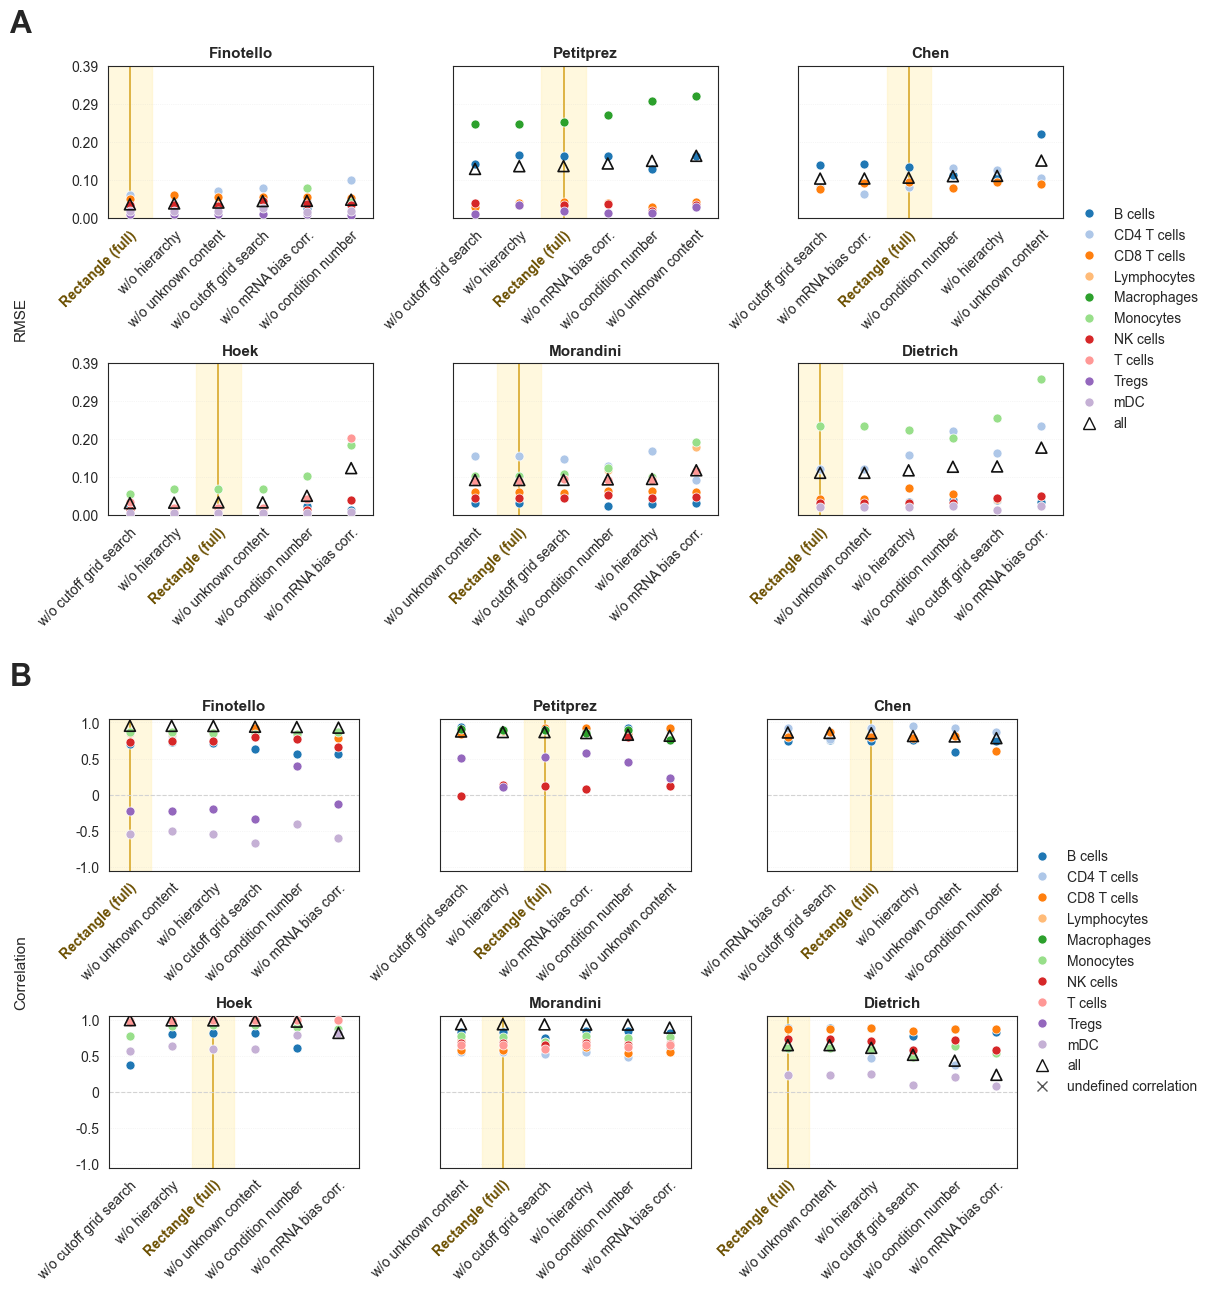

In [11]:
# Same layout as fig_suppl1_celltype_method_rmse_correlation (figure_2.ipynb), with ablations in place of methods
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

sns.set_style('white')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

ablation_labels = {
    'full': 'Rectangle (full)',
    'no_mrna_bias': 'w/o mRNA bias corr.',
    'no_grid_search': 'w/o cutoff grid search',
    'no_unknown': 'w/o unknown content',
    'no_hierarchy': 'w/o hierarchy',
    'no_condition_number': 'w/o condition number',
}
bulk_labels = {
    'finotello': 'Finotello',
    'petitprez': 'Petitprez',
    'chen': 'Chen',
    'hoek': 'Hoek',
    'morandini': 'Morandini',
    'dietrich': 'Dietrich',
}
# True: order ablations per panel by their 'all' value, as in the methods figure; False: same order in every panel
sort_by_overall = True

df_plot = pd.read_csv(ablation_root / 'celltype_metrics.csv')
plot_ablations = [a for a in ablation_order if a in set(df_plot['ablation'])]
plot_datasets = [d for d in dataset_order if d in set(df_plot['bulk_ds'])]

cell_type_order = sorted([ct for ct in df_plot['cell_type'].dropna().unique() if ct != 'all']) + ['all']
palette = dict(zip(cell_type_order, sns.color_palette('tab20', n_colors=len(cell_type_order))))
palette['all'] = '#111111'

plot_specs = [
    ('RMSE', 'RMSE', 'A'),
    ('cor', 'Correlation', 'B'),
]
combined_out_path = '../figures/fig_suppl_ablation_celltype_rmse_correlation'

n_cols = 3
n_rows = int(np.ceil(len(plot_datasets) / n_cols))
fig = plt.figure(figsize=(4.0 * n_cols, (2.6 * n_rows + 1.2) * len(plot_specs)), facecolor='white', layout='constrained')
subfigs = fig.subfigures(len(plot_specs), 1, hspace=0.04)

for subfig, (metric_col, y_label, panel_letter) in zip(subfigs, plot_specs):
    ascending = metric_col == 'RMSE'

    subfig.set_facecolor('white')
    axes = subfig.subplots(n_rows, n_cols, sharey=True)
    axes = np.array(axes).reshape(-1)

    metric_max = float(df_plot[metric_col].max(skipna=True))
    if metric_col == 'cor':
        y_lim = (-1.05, 1.05)
        y_ticks = list(np.linspace(-1, 1, 5))
        y_tick_labels = [f'{v:.1f}' if v != 0 else '0' for v in y_ticks]
    else:
        y_lim = (0, max(metric_max * 1.12, 0.1))
        y_ticks = list(np.linspace(0, y_lim[1], 5))
        y_tick_labels = [f'{v:.2f}' for v in y_ticks]

    for i, (ax, bulk) in enumerate(zip(axes, plot_datasets)):
        ax.set_facecolor('white')
        # with a fixed order the ablation names are only needed on the bottom panel of each column
        show_labels = sort_by_overall or i + n_cols >= len(plot_datasets)
        sub = df_plot[df_plot['bulk_ds'] == bulk]
        plot_ablation_order = plot_ablations
        if sort_by_overall:
            all_metric = sub[sub['cell_type'] == 'all'].set_index('ablation')[metric_col].reindex(plot_ablations)
            # Exact metric ties: full Rectangle first, then notebook ablation order.
            ranking = pd.DataFrame({
                'metric': all_metric,
                'full_priority': [0 if a == 'full' else 1 for a in all_metric.index],
                'original_order': np.arange(len(all_metric)),
            })
            plot_ablation_order = ranking.sort_values(
                ['metric', 'full_priority', 'original_order'],
                ascending=[ascending, True, True], na_position='last',
            ).index.tolist()
        if 'full' in plot_ablation_order:
            full_idx = plot_ablation_order.index('full')
            ax.axvspan(full_idx - 0.5, full_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
            ax.axvline(full_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)

        for ct in cell_type_order:
            d_ct = sub[sub['cell_type'] == ct]
            if d_ct.empty:
                continue
            x_vals = np.array([plot_ablation_order.index(a) for a in d_ct['ablation']], dtype=int)
            y_vals = d_ct[metric_col]
            marker_style = '^' if ct == 'all' else 'o'
            marker_size = 62 if ct == 'all' else 42
            face_color = 'none' if ct == 'all' else palette[ct]
            edge_color = '#111111' if ct == 'all' else 'white'
            line_width = 1.2 if ct == 'all' else 0.5

            valid_mask = y_vals.notna().to_numpy()
            if valid_mask.any():
                ax.scatter(
                    x_vals[valid_mask],
                    y_vals.to_numpy()[valid_mask],
                    s=marker_size,
                    marker=marker_style,
                    facecolors=face_color,
                    edgecolors=edge_color,
                    linewidths=line_width,
                    zorder=3
                )
            if metric_col == 'cor' and (~valid_mask).any():
                nan_y = y_lim[0] + 0.03
                nan_marker_color = '#111111' if ct == 'all' else palette[ct]
                ax.scatter(
                    x_vals[~valid_mask],
                    np.full((~valid_mask).sum(), nan_y, dtype=float),
                    s=30,
                    marker='x',
                    color=nan_marker_color,
                    linewidths=1.1,
                    zorder=4,
                )

        if metric_col == 'cor':
            ax.axhline(0, linestyle='--', color='lightgrey', linewidth=0.8, zorder=1)
        ax.set_title(bulk_labels[bulk], fontsize=11, weight='bold')
        ax.set_xlim(-0.5, len(plot_ablation_order) - 0.5)
        ax.set_ylim(*y_lim)
        ax.set_xticks(range(len(plot_ablation_order)))
        ax.set_xticklabels([ablation_labels[a] if show_labels else '' for a in plot_ablation_order],
                           rotation=45, ha='right', rotation_mode='anchor')
        for lbl, a in zip(ax.get_xticklabels(), plot_ablation_order):
            if a == 'full':
                lbl.set_fontweight('bold')
                lbl.set_color('#6b4f00')
        ax.grid(axis='y', linestyle=':', alpha=0.35)

    for ax in axes[:len(plot_datasets)]:
        ax.set_yticks(y_ticks)
        ax.set_yticklabels(y_tick_labels)
    for ax in axes[len(plot_datasets):]:
        ax.axis('off')

    subfig.supylabel(y_label, fontsize=11)
    subfig.suptitle(panel_letter, x=0.0, ha='left', fontsize=22, fontweight='bold')
    legend_handles = [
        Line2D([0], [0], marker='^', linestyle='None', markerfacecolor='none', markeredgecolor='#111111', markersize=8, label='all') if ct == 'all'
        else Line2D([0], [0], marker='o', linestyle='None', markerfacecolor=palette[ct], markeredgecolor='white', markersize=7, label=ct)
        for ct in cell_type_order
    ]
    if metric_col == 'cor':
        legend_handles.append(
            Line2D([0], [0], marker='x', linestyle='None', color='#555555', markersize=7, label='undefined correlation')
        )
    spare_axes = axes[len(plot_datasets):]
    if len(spare_axes):
        spare_axes[0].legend(handles=legend_handles, loc='center', ncol=2, frameon=False,
                             handletextpad=0.4, columnspacing=1.2, labelspacing=0.7)
    else:
        subfig.legend(handles=legend_handles, loc='outside right center', frameon=False)

for ext in ('pdf', 'png'):
    fig.savefig(f'{combined_out_path}.{ext}', facecolor='white', bbox_inches='tight', dpi=300)
plt.show()

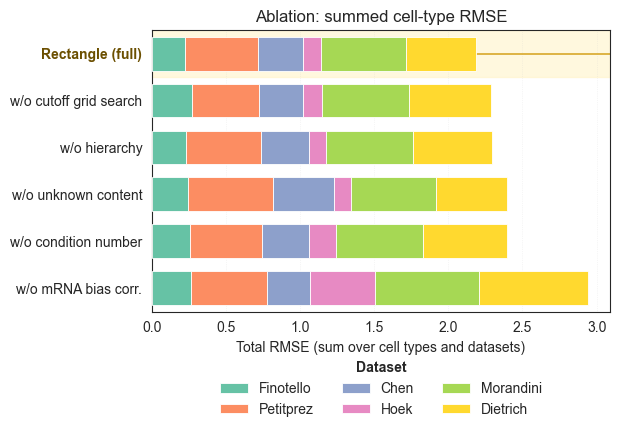

bulk_ds,finotello,petitprez,chen,hoek,morandini,dietrich,total_rmse
ablation,,,,,,,
full,0.219485,0.497261,0.303951,0.117134,0.574990,0.475869,2.188690
no_grid_search,0.270283,0.454933,0.291782,0.129372,0.589081,0.551219,2.286669
no_hierarchy,0.229902,0.508952,0.322800,0.114812,0.583520,0.531210,2.291197
no_unknown,0.241552,0.577225,0.408571,0.117134,0.574306,0.475869,2.394657
no_condition_number,0.259290,0.485045,0.315808,0.181373,0.590388,0.564545,2.396448
no_mrna_bias,0.266343,0.512097,0.289685,0.439374,0.702117,0.733619,2.943235


In [12]:
# Figure 2 style: sum per-cell-type RMSEs within each dataset, then stack datasets.
# Exclude the pooled 'all' metric to avoid counting the same errors twice.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rmse_sum_root = Path('../output/ablation_hao_sub_rectangle_1_7_0')
rmse_sum_ablations = ['full', 'no_mrna_bias', 'no_grid_search', 'no_unknown', 'no_hierarchy', 'no_condition_number']
rmse_sum_datasets = ['finotello', 'petitprez', 'chen', 'hoek', 'morandini', 'dietrich']
rmse_sum_labels = {
    'full': 'Rectangle (full)',
    'no_mrna_bias': 'w/o mRNA bias corr.',
    'no_grid_search': 'w/o cutoff grid search',
    'no_unknown': 'w/o unknown content',
    'no_hierarchy': 'w/o hierarchy',
    'no_condition_number': 'w/o condition number',
}
rmse_sum_dataset_labels = {
    'finotello': 'Finotello', 'petitprez': 'Petitprez', 'chen': 'Chen',
    'hoek': 'Hoek', 'morandini': 'Morandini', 'dietrich': 'Dietrich',
}
rmse_sum_metrics = pd.read_csv(rmse_sum_root / 'celltype_metrics.csv')
rmse_sum_cells = rmse_sum_metrics.loc[
    rmse_sum_metrics['cell_type'].ne('all')
    & rmse_sum_metrics['ablation'].isin(rmse_sum_ablations)
    & rmse_sum_metrics['bulk_ds'].isin(rmse_sum_datasets)
].copy()
if rmse_sum_cells.duplicated(['cell_type', 'ablation', 'bulk_ds']).any():
    raise ValueError('Duplicate cell-type metrics; rerun evaluation.')

rmse_sum_cells['finite_rmse'] = np.isfinite(rmse_sum_cells['RMSE'])
grouped_rmse = rmse_sum_cells.groupby(['ablation', 'bulk_ds'])
rmse_sum_pivot = grouped_rmse['RMSE'].sum(min_count=1).unstack('bulk_ds').reindex(
    index=rmse_sum_ablations, columns=rmse_sum_datasets,
)
cell_counts = grouped_rmse.size().unstack('bulk_ds').reindex(
    index=rmse_sum_ablations, columns=rmse_sum_datasets,
)
finite_counts = grouped_rmse['finite_rmse'].sum().unstack('bulk_ds').reindex(
    index=rmse_sum_ablations, columns=rmse_sum_datasets,
)
# Every ablation must cover the same cell types and all datasets.
expected_cell_counts = cell_counts.max(axis=0)
complete_rmse = (
    cell_counts.eq(expected_cell_counts, axis='columns')
    & finite_counts.eq(cell_counts)
    & cell_counts.gt(0)
    & np.isfinite(rmse_sum_pivot)
).all(axis=1)
if not complete_rmse.any():
    raise ValueError('No ablation has complete finite RMSEs across all six datasets.')
if not complete_rmse.all():
    print('Incomplete RMSE sums excluded:', complete_rmse.index[~complete_rmse].tolist())

rmse_sum_pivot = rmse_sum_pivot.loc[complete_rmse]
rmse_sum_totals = rmse_sum_pivot.sum(axis=1)
rmse_sum_sort = pd.DataFrame({
    'total': rmse_sum_totals,
    'full_priority': [0 if a == 'full' else 1 for a in rmse_sum_pivot.index],
    'original_order': np.arange(len(rmse_sum_pivot)),
})
rmse_sum_order = rmse_sum_sort.sort_values(
    ['total', 'full_priority', 'original_order'],
).index.tolist()
rmse_sum_pivot = rmse_sum_pivot.loc[rmse_sum_order]
rmse_sum_table = rmse_sum_pivot.assign(total_rmse=rmse_sum_totals)
rmse_sum_table.to_csv(rmse_sum_root / 'ablation_rmse_sums.csv')

sns.set_style('white')
dataset_colors = dict(zip(
    rmse_sum_datasets, sns.color_palette('Set2', n_colors=len(rmse_sum_datasets)),
))
fig_rmse_sum, ax_rmse_sum = plt.subplots(figsize=(6.3, 5.2), facecolor='white')
ax_rmse_sum.set_facecolor('white')
if 'full' in rmse_sum_order:
    full_idx = rmse_sum_order.index('full')
    ax_rmse_sum.axhspan(full_idx - 0.5, full_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
    ax_rmse_sum.axhline(full_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)

left = np.zeros(len(rmse_sum_order))
y = np.arange(len(rmse_sum_order))
for dataset in rmse_sum_datasets:
    values = rmse_sum_pivot[dataset].to_numpy(dtype=float)
    ax_rmse_sum.barh(
        y, values, left=left, height=0.72, color=dataset_colors[dataset],
        edgecolor='white', linewidth=0.6, label=rmse_sum_dataset_labels[dataset], zorder=3,
    )
    left += values

ax_rmse_sum.set_ylim(-0.5, len(rmse_sum_order) - 0.5)
ax_rmse_sum.set_yticks(y)
ax_rmse_sum.set_yticklabels([rmse_sum_labels[a] for a in rmse_sum_order])
ax_rmse_sum.invert_yaxis()
for label, ablation in zip(ax_rmse_sum.get_yticklabels(), rmse_sum_order):
    if ablation == 'full':
        label.set_fontweight('bold')
        label.set_color('#6b4f00')
ax_rmse_sum.set_xlabel('Total RMSE (sum over cell types and datasets)')
ax_rmse_sum.set_title('Ablation: summed cell-type RMSE')
ax_rmse_sum.grid(axis='x', linestyle=':', alpha=0.35)
legend = ax_rmse_sum.legend(
    loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, title='Dataset',
)
legend.get_title().set_fontweight('bold')
fig_rmse_sum.tight_layout(rect=[0, 0.12, 1, 1])
for extension in ('pdf', 'png'):
    fig_rmse_sum.savefig(
        f'../figures/fig_suppl_ablation_dataset_rmse_stacked.{extension}',
        facecolor='white', bbox_inches='tight', dpi=300,
    )
plt.show()
rmse_sum_table


## Statistical testing of the ablations

Every dataset is deconvolved under every variant, so each ablation is compared with full Rectangle **within the same dataset**. The independent units are the **six datasets**. Cell types within a dataset share samples, a reference and a mixing structure, so treating them as independent replicates would make p-values too optimistic.

Paired difference per dataset, oriented so that **positive means the ablation hurts**:
- Correlation: $\Delta = \operatorname{atanh}(r_\mathrm{full}) - \operatorname{atanh}(r_\mathrm{ablated})$ (Fisher z)
- RMSE: $\Delta = \log(\mathrm{RMSE}_\mathrm{ablated} / \mathrm{RMSE}_\mathrm{full})$ (log ratio, so datasets with different error scales count equally)

Analyses:
1. **Primary, dataset level** (overall metric per dataset): one-sided Wilcoxon signed-rank test of $\Delta > 0$ per ablation, corrected over all 5 ablations $\times$ 2 metrics (Holm and Benjamini-Hochberg). Reported with the win rate (sign test), the Hodges-Lehmann estimate, a bootstrap CI of the median $\Delta$, and a Friedman test over all six variants.
2. **Bayesian signed-rank test with a ROPE** (Benavoli et al., 2017): P(ablation worse), P(practically equivalent), P(ablation better). This separates "the module doesn't matter" from "an effect could not be detected".
3. **Secondary, cell-type level**: linear mixed model on all cell-type metrics with random intercepts for dataset and cell type within dataset. Each ablation is contrasted against full Rectangle and Holm-corrected within each metric.

With n = 6 datasets the smallest possible one-sided Wilcoxon p is 1/64 $\approx$ 0.016. Holm over 10 tests therefore cannot go below 0.16, so dataset-level conclusions should rest on effect sizes, win rates and the Bayesian probabilities, not on adjusted p-values alone.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, binomtest, friedmanchisquare
from statsmodels.stats.multitest import multipletests

stats_root = Path('../output/ablation_hao_sub_rectangle_1_7_0')
stats_ablations = ['no_mrna_bias', 'no_grid_search', 'no_unknown', 'no_hierarchy', 'no_condition_number']
stats_datasets = ['finotello', 'petitprez', 'chen', 'hoek', 'morandini', 'dietrich']
stats_variants = ['full'] + stats_ablations
# ROPE for the Bayesian test, on an interpretable scale: |delta r| < 0.01 and RMSE within +-5 %
rope_correlation = 0.01
rope_rmse_log_ratio = np.log(1.05)
rng = np.random.default_rng(0)

stats_metrics = pd.read_csv(stats_root / 'celltype_metrics.csv')
overall = (stats_metrics[stats_metrics['cell_type'].eq('all')]
           .set_index(['ablation', 'bulk_ds'])[['cor', 'RMSE']]
           .reindex(pd.MultiIndex.from_product([stats_variants, stats_datasets], names=['ablation', 'bulk_ds'])))
if overall.isna().any().any():
    raise ValueError(f'Missing overall metrics:\n{overall[overall.isna().any(axis=1)]}')


def fisher_z(r):
    return np.arctanh(np.clip(r, -0.999999, 0.999999))


def paired_deltas(metric, scale):
    table = overall[metric].unstack('bulk_ds')
    full, ablated = table.loc['full'], table.loc[stats_ablations]
    if metric == 'cor':
        # positive = ablation lowers the correlation
        return (fisher_z(full) - fisher_z(ablated)) if scale == 'transformed' else (full - ablated)
    # positive = ablation raises the error
    return np.log(ablated / full)


def hodges_lehmann(x):
    walsh = [(x[i] + x[j]) / 2 for i in range(len(x)) for j in range(i, len(x))]
    return float(np.median(walsh))


def bootstrap_median_ci(x, n_boot=20000):
    medians = np.median(rng.choice(x, size=(n_boot, len(x)), replace=True), axis=1)
    return np.percentile(medians, [2.5, 97.5])


def bayesian_signed_rank(x, rope, prior_strength=0.5, n_samples=50000):
    # Benavoli et al. 2017 (as in baycomp.SignedRankTest): Dirichlet process posterior with a
    # pseudo-observation at 0; returns the share of posterior samples in which each region has the most mass
    z = np.concatenate(([0.0], np.asarray(x, dtype=float)))
    alpha = np.ones(len(z))
    alpha[0] = prior_strength
    weights = rng.dirichlet(alpha, n_samples)
    walsh = z[:, None] + z[None, :]
    regions = [walsh < -2 * rope, np.abs(walsh) <= 2 * rope, walsh > 2 * rope]
    mass = np.stack([np.einsum('si,ij,sj->s', weights, region.astype(float), weights) for region in regions], axis=1)
    winner = mass.argmax(axis=1)
    return [float(np.mean(winner == k)) for k in range(3)]  # better, equivalent, worse


metric_labels = {'cor': 'Correlation', 'RMSE': 'RMSE'}
delta_tables = {metric: paired_deltas(metric, 'transformed') for metric in metric_labels}
rows = []
for metric, deltas in delta_tables.items():
    raw = paired_deltas(metric, 'raw')
    rope = rope_correlation if metric == 'cor' else rope_rmse_log_ratio
    for ablation in stats_ablations:
        x = deltas.loc[ablation].to_numpy(dtype=float)
        worse, better = int((x > 0).sum()), int((x < 0).sum())
        nonzero = x[x != 0]
        wilcoxon_p = wilcoxon(nonzero, alternative='greater').pvalue if len(nonzero) else np.nan
        sign_p = binomtest(worse, worse + better, 0.5, alternative='greater').pvalue if worse + better else np.nan
        ci_low, ci_high = bootstrap_median_ci(x)
        p_better, p_equivalent, p_worse = bayesian_signed_rank(raw.loc[ablation].to_numpy(dtype=float), rope)
        rows.append({
            'metric': metric_labels[metric], 'ablation': ablation, 'n_datasets': len(x),
            'datasets_worse': worse, 'datasets_better': better, 'datasets_tied': len(x) - worse - better,
            'median_delta': float(np.median(x)), 'median_delta_ci_low': ci_low, 'median_delta_ci_high': ci_high,
            'hodges_lehmann': hodges_lehmann(x),
            'wilcoxon_p': wilcoxon_p, 'sign_test_p': sign_p,
            'P_ablation_worse': p_worse, 'P_equivalent': p_equivalent, 'P_ablation_better': p_better,
        })

dataset_stats = pd.DataFrame(rows)
valid = dataset_stats['wilcoxon_p'].notna()
dataset_stats.loc[valid, 'wilcoxon_p_holm'] = multipletests(dataset_stats.loc[valid, 'wilcoxon_p'], method='holm')[1]
dataset_stats.loc[valid, 'wilcoxon_p_bh'] = multipletests(dataset_stats.loc[valid, 'wilcoxon_p'], method='fdr_bh')[1]
dataset_stats.to_csv(stats_root / 'statistics_dataset_level.csv', index=False)

# Global test: do the six variants differ at all? Datasets are the blocks.
for metric in metric_labels:
    table = overall[metric].unstack('bulk_ds')
    friedman = friedmanchisquare(*[table.loc[v].to_numpy() for v in stats_variants])
    print(f'Friedman ({metric_labels[metric]}, {len(stats_variants)} variants x {len(stats_datasets)} datasets): '
          f'chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.3g}')

dataset_stats.round(4)

Friedman (Correlation, 6 variants x 6 datasets): chi2 = 12.60, p = 0.0275
Friedman (RMSE, 6 variants x 6 datasets): chi2 = 9.71, p = 0.0838


,metric,ablation,n_datasets,datasets_worse,datasets_better,datasets_tied,median_delta,median_delta_ci_low,median_delta_ci_high,hodges_lehmann,wilcoxon_p,sign_test_p,P_ablation_worse,P_equivalent,P_ablation_better,wilcoxon_p_holm,wilcoxon_p_bh
0,Correlation,no_mrna_bias,6,5,1,0,0.2552,0.0061,0.9832,0.2819,0.0312,0.1094,0.9588,0.0412,0.0000,0.2500,0.0781
1,Correlation,no_grid_search,6,3,3,0,-0.0032,-0.1152,0.1650,0.0042,0.5000,0.6562,0.1841,0.8159,0.0000,0.8438,0.5000
2,Correlation,no_unknown,6,3,1,2,0.0064,-0.0010,0.1576,0.0705,0.1250,0.3125,0.4877,0.5123,0.0000,0.5000,0.1562
3,Correlation,no_hierarchy,6,4,2,0,0.0328,-0.0119,0.0944,0.0328,0.0781,0.3438,0.4880,0.5120,0.0000,0.4688,0.1302
4,Correlation,no_condition_number,6,6,0,0,0.1863,0.0830,0.3807,0.2062,0.0156,0.0156,0.9859,0.0141,0.0000,0.1562,0.0781
5,RMSE,no_mrna_bias,6,5,1,0,0.2359,0.0136,0.8887,0.2454,0.0312,0.1094,0.9574,0.0426,0.0000,0.2500,0.0781
6,RMSE,no_grid_search,6,3,3,0,-0.0099,-0.0573,0.1786,0.0414,0.4219,0.6562,0.4144,0.5480,0.0376,0.8438,0.4688
7,RMSE,no_unknown,6,3,1,2,0.0611,-0.0005,0.2672,0.0904,0.1250,0.3125,0.8036,0.1964,0.0000,0.5000,0.1562
8,RMSE,no_hierarchy,6,4,2,0,0.0363,-0.0119,0.0602,0.0292,0.0781,0.3438,0.0608,0.9392,0.0000,0.4688,0.1302
9,RMSE,no_condition_number,6,6,0,0,0.1149,0.0265,0.3554,0.1549,0.0156,0.0156,0.9457,0.0543,0.0000,0.1562,0.0781


In [14]:
# Secondary: all cell-type metrics in one linear mixed model.
# y ~ ablation + (1 | dataset) + (1 | dataset:cell type); full Rectangle is the reference level.
import warnings
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm

cell_level = stats_metrics[stats_metrics['cell_type'].ne('all') & stats_metrics['ablation'].isin(stats_variants)].copy()
cell_level['ablation'] = pd.Categorical(cell_level['ablation'], categories=stats_variants)
mixed_rows = []
for metric in metric_labels:
    data = cell_level.dropna(subset=[metric]).copy()
    data['y'] = fisher_z(data[metric]) if metric == 'cor' else np.log(data[metric])
    data = data[np.isfinite(data['y'])]
    model = smf.mixedlm('y ~ C(ablation, Treatment("full"))', data, groups='bulk_ds',
                        re_formula='1', vc_formula={'cell_type': '0 + C(cell_type)'})
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = model.fit(reml=True, method=['lbfgs', 'powell'])
    print(f'{metric_labels[metric]}: {len(data)} rows, {data["bulk_ds"].nunique()} datasets, converged={fit.converged}')
    ci = fit.conf_int()
    # transform-free check: in how many dataset x cell type pairs is the ablation worse?
    paired = data.pivot_table(index=['bulk_ds', 'cell_type'], columns='ablation', values=metric, observed=True)
    metric_rows = []
    for ablation in stats_ablations:
        term = f'C(ablation, Treatment("full"))[T.{ablation}]'
        estimate, se = fit.params[term], fit.bse[term]
        # oriented like the dataset-level deltas: positive = ablation hurts
        sign = -1 if metric == 'cor' else 1
        metric_rows.append({
            'metric': metric_labels[metric], 'ablation': ablation,
            'effect': sign * estimate,
            'effect_ci_low': sign * (ci.loc[term, 1] if sign < 0 else ci.loc[term, 0]),
            'effect_ci_high': sign * (ci.loc[term, 0] if sign < 0 else ci.loc[term, 1]),
            'p_one_sided': norm.sf(sign * estimate / se),
            'celltypes_worse': int((sign * (paired[ablation] - paired['full']) > 0).sum()),
            'celltypes_compared': int(paired[[ablation, 'full']].notna().all(axis=1).sum()),
        })
    metric_rows = pd.DataFrame(metric_rows)
    # Holm over the five contrasts against full (a conservative stand-in for Dunnett)
    metric_rows['p_holm'] = multipletests(metric_rows['p_one_sided'], method='holm')[1]
    mixed_rows.append(metric_rows)

mixed_stats = pd.concat(mixed_rows, ignore_index=True)
mixed_stats.to_csv(stats_root / 'statistics_mixed_model.csv', index=False)
mixed_stats.round(4)

Correlation: 198 rows, 6 datasets, converged=True
RMSE: 198 rows, 6 datasets, converged=True


,metric,ablation,effect,effect_ci_low,effect_ci_high,p_one_sided,celltypes_worse,celltypes_compared,p_holm
0,Correlation,no_mrna_bias,0.0432,-0.0421,0.1285,0.1604,22,33,0.6415
1,Correlation,no_grid_search,0.1417,0.0565,0.2270,0.0006,25,33,0.0028
2,Correlation,no_unknown,0.0288,-0.0564,0.1141,0.2537,9,33,0.6415
3,Correlation,no_hierarchy,0.0369,-0.0483,0.1222,0.1979,14,33,0.6415
4,Correlation,no_condition_number,0.0253,-0.0600,0.1105,0.2806,23,33,0.6415
5,RMSE,no_mrna_bias,0.2585,0.1214,0.3956,0.0001,20,33,0.0005
6,RMSE,no_grid_search,0.0660,-0.0711,0.2031,0.1727,23,33,0.6910
7,RMSE,no_unknown,0.0583,-0.0788,0.1954,0.2023,12,33,0.6910
8,RMSE,no_hierarchy,0.0486,-0.0885,0.1857,0.2435,16,33,0.6910
9,RMSE,no_condition_number,0.0481,-0.0890,0.1852,0.2458,20,33,0.6910


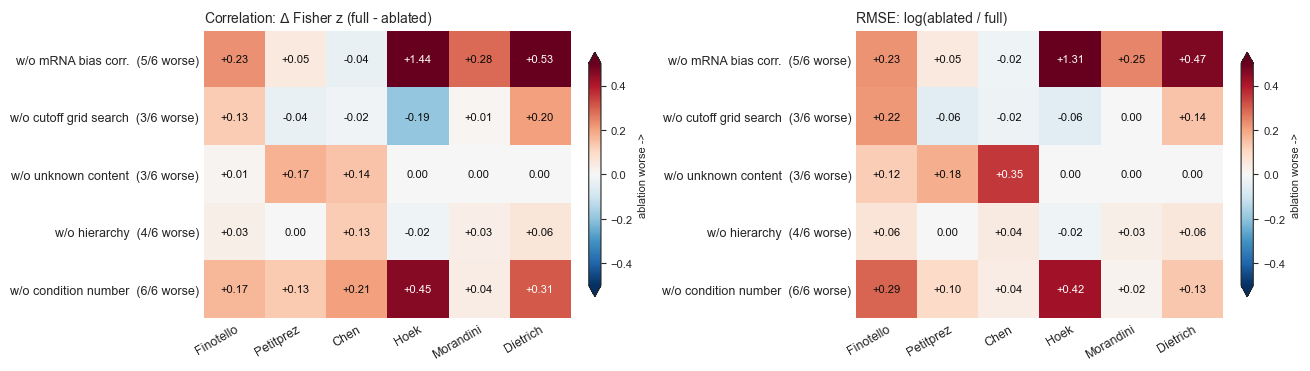

In [15]:
# Paired differences per dataset: red = ablation worse than full Rectangle, blue = better
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

stats_ablation_labels = {
    'no_mrna_bias': 'w/o mRNA bias corr.',
    'no_grid_search': 'w/o cutoff grid search',
    'no_unknown': 'w/o unknown content',
    'no_hierarchy': 'w/o hierarchy',
    'no_condition_number': 'w/o condition number',
}
stats_dataset_labels = {'finotello': 'Finotello', 'petitprez': 'Petitprez', 'chen': 'Chen',
                        'hoek': 'Hoek', 'morandini': 'Morandini', 'dietrich': 'Dietrich'}
panels = [
    ('cor', r'Correlation: $\Delta$ Fisher z (full - ablated)'),
    ('RMSE', 'RMSE: log(ablated / full)'),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), facecolor='white', layout='constrained')
for ax, (metric, title) in zip(axes, panels):
    deltas = delta_tables[metric].loc[stats_ablations, stats_datasets]
    summary = dataset_stats[dataset_stats['metric'].eq(metric_labels[metric])].set_index('ablation')
    # color scale capped at 0.5 so one extreme dataset does not wash out the rest; the numbers stay exact
    limit = min(float(np.nanmax(np.abs(deltas.to_numpy()))), 0.5)
    image = ax.imshow(deltas.to_numpy(), cmap='RdBu_r', norm=TwoSlopeNorm(0, -limit, limit), aspect='auto')
    for i in range(deltas.shape[0]):
        for j in range(deltas.shape[1]):
            value = deltas.iat[i, j]
            text = '0.00' if abs(value) < 0.005 else f'{value:+.2f}'
            ax.text(j, i, text, ha='center', va='center', fontsize=8,
                    color='white' if abs(value) > 0.6 * limit else '#0b0b0b')
    ax.set_xticks(range(len(stats_datasets)))
    ax.set_xticklabels([stats_dataset_labels[d] for d in stats_datasets], fontsize=9,
                       rotation=30, ha='right', rotation_mode='anchor')
    ax.set_yticks(range(len(stats_ablations)))
    ax.set_yticklabels([
        f'{stats_ablation_labels[a]}  ({summary.loc[a, "datasets_worse"]}/{summary.loc[a, "n_datasets"]} worse)'
        for a in stats_ablations
    ], fontsize=9)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_title(title, fontsize=10, loc='left')
    colorbar = fig.colorbar(image, ax=ax, shrink=0.85, extend='both')
    colorbar.ax.tick_params(labelsize=8)
    colorbar.set_label('ablation worse ->', fontsize=8)
for ext in ('pdf', 'png'):
    fig.savefig(f'../figures/fig_suppl_ablation_delta_heatmap.{ext}', facecolor='white', bbox_inches='tight', dpi=300)
plt.show()

### Sample-level test (main test for the manuscript)

With six datasets the dataset-level Wilcoxon test cannot reach significance after correction (smallest possible one-sided p = 1/64), so the comparison is made on the **bulk samples**, which are deconvolved under every variant and therefore paired.

- Per sample: RMSE across its cell types; paired difference $D = \log(\mathrm{RMSE}_\mathrm{ablated} / \mathrm{RMSE}_\mathrm{full})$, positive means the ablation hurts.
- Statistic: mean over the six datasets of the per-dataset mean $D$, so every dataset counts equally (Morandini's 156 samples do not outweigh Finotello's 9).
- Two-sided stratified sign-flip permutation test (20,000 permutations; the signs of the paired differences are exchangeable under "no effect"), Holm-corrected over the five ablations.
- Effect reported as % change in (geometric mean) per-sample RMSE, with a 95% bootstrap CI that resamples samples within datasets.

Correlation stays at the dataset level: a per-sample correlation over 4-12 cell types is too unstable.


In [ ]:
# Sample-level stratified sign-flip permutation test (needs `prepare`, `ablation_root` from the evaluation cell)
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

sample_ablations = ['no_mrna_bias', 'no_grid_search', 'no_unknown', 'no_hierarchy', 'no_condition_number']
sample_datasets = ['finotello', 'petitprez', 'chen', 'hoek', 'morandini', 'dietrich']
n_permutations = 20000
rng = np.random.default_rng(0)

rows = []
for ablation in ['full'] + sample_ablations:
    for dataset in sample_datasets:
        gold, estimated = prepare[dataset](pd.read_csv(ablation_root / ablation / f'{dataset}.csv', index_col=0))
        for sample in gold.columns:
            truth, prediction = gold[sample].to_numpy(float), estimated[sample].to_numpy(float)
            valid = np.isfinite(truth) & np.isfinite(prediction)
            if not valid.any():
                raise ValueError(f'{ablation}/{dataset}/{sample}: no finite cell-type pairs')
            rows.append((ablation, dataset, sample, float(np.sqrt(np.mean((prediction[valid] - truth[valid]) ** 2)))))
sample_rmse = pd.DataFrame(rows, columns=['ablation', 'bulk_ds', 'sample', 'RMSE'])
sample_rmse.to_csv(ablation_root / 'sample_rmse.csv', index=False)
paired = sample_rmse.pivot_table(index=['bulk_ds', 'sample'], columns='ablation', values='RMSE')

test_rows = []
for ablation in sample_ablations:
    log_ratio = np.log(paired[ablation] / paired['full'])
    groups = [log_ratio.xs(dataset, level='bulk_ds').to_numpy() for dataset in sample_datasets]
    statistic = np.mean([g.mean() for g in groups])
    null = np.mean([(rng.choice([-1, 1], size=(n_permutations, len(g))) * g).mean(axis=1) for g in groups], axis=0)
    p_value = (1 + np.sum(np.abs(null) >= abs(statistic))) / (n_permutations + 1)
    bootstrap = np.mean([rng.choice(g, size=(n_permutations, len(g)), replace=True).mean(axis=1) for g in groups], axis=0)
    ci_low, ci_high = np.percentile(bootstrap, [2.5, 97.5])
    test_rows.append({
        'ablation': ablation, 'n_samples': len(log_ratio),
        'rmse_change_pct': np.expm1(statistic) * 100,
        'ci_low_pct': np.expm1(ci_low) * 100, 'ci_high_pct': np.expm1(ci_high) * 100,
        'p_permutation': p_value,
        'samples_worse': int((log_ratio > 0).sum()), 'samples_better': int((log_ratio < 0).sum()),
        'datasets_worse': sum(g.mean() > 0 for g in groups),
        **{f'{dataset}_change_pct': np.expm1(g.mean()) * 100 for dataset, g in zip(sample_datasets, groups)},
    })
sample_stats = pd.DataFrame(test_rows)
sample_stats['p_holm'] = multipletests(sample_stats['p_permutation'], method='holm')[1]
sample_stats.to_csv(ablation_root / 'statistics_sample_level.csv', index=False)
print(f'{len(paired)} paired samples; smallest attainable p = {1 / (n_permutations + 1):.1e}')
sample_stats.round(4)
